# mcl-PHAs / DTS data / Tandelta Predictor

**Author:** Lab of Farm Structures
**Date:** 2026-11

## Import libraries

In [1]:
import pandas as pd
import kennard_stone as ks
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import math
import shap
from prince import FAMD
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, GroupKFold, KFold, RepeatedKFold, cross_val_predict, LeaveOneGroupOut
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import seaborn as sns
from jaqpotpy import Jaqpot
from jaqpotpy.datasets import JaqpotTabularDataset
from jaqpotpy.models.sklearn import SklearnModel
from jaqpotpy.doa import Leverage, BoundingBox, MeanVar
from jaqpotpy.models.xgboost import XGBoostModel
from sklearn.model_selection import GroupShuffleSplit
from scipy.stats import pearsonr
from scipy.spatial.distance import cdist
from sklearn.model_selection import cross_validate
from sklearn.base import clone
import warnings; warnings.filterwarnings("ignore")

C:\Users\leoni\anaconda3\envs\polymer-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\leoni\anaconda3\envs\polymer-ml\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load data

In [21]:
model_stor = 'rheological_DTS_mcl_tandelta_LM'

df_stor = pd.read_csv(f'{model_stor}.csv')
df_stor.head()

,study_id,instance,3hb_ratio_mol,3ho_ratio_mol,3hdd_ratio_mol,3hv_ratio_mol,mcl_pha_ratio_mol,3httd_ratio_mol,unsaturated_monomer_ratio_mol,uknown_monomer_ratio_mol,additive1_percentage_wt,additive1_type,final_pha_percentage_wt,frequency_experimental_fixed_hz,temperature,tan_delta,log_tan_delta
0,3,1,0.0,86.0,0.0,0.0,100.0,0,0.0,14.0,0.0,no_additive,100.0,1.0,-45.0,0.106,-0.974694
1,3,1,0.0,86.0,0.0,0.0,100.0,0,0.0,14.0,0.0,no_additive,100.0,1.0,-35.0,0.353,-0.452225
2,3,1,0.0,86.0,0.0,0.0,100.0,0,0.0,14.0,0.0,no_additive,100.0,1.0,-25.0,2.153,0.333044
3,3,1,0.0,86.0,0.0,0.0,100.0,0,0.0,14.0,0.0,no_additive,100.0,1.0,-15.0,0.914,-0.039054
4,3,1,0.0,86.0,0.0,0.0,100.0,0,0.0,14.0,0.0,no_additive,100.0,1.0,-5.0,0.552,-0.258061


In [23]:
df_stor.columns

Index(['study_id', 'instance', '3hb_ratio_mol', '3ho_ratio_mol',
       '3hdd_ratio_mol', '3hv_ratio_mol', 'mcl_pha_ratio_mol',
       '3httd_ratio_mol', 'unsaturated_monomer_ratio_mol',
       'uknown_monomer_ratio_mol', 'additive1_percentage_wt', 'additive1_type',
       'final_pha_percentage_wt', 'frequency_experimental_fixed_hz',
       'temperature', 'tan_delta', 'log_tan_delta'],
      dtype='str')

## Select Features and Target

In [26]:
features = [
 'study_id', 'instance', 'mcl_pha_ratio_mol', '3ho_ratio_mol',
       'unsaturated_monomer_ratio_mol', 'additive1_percentage_wt',
       'final_pha_percentage_wt', 'frequency_experimental_fixed_hz', 'additive1_type',
       'temperature'
]

target = 'log_tan_delta'

measure_unit = ' '

In [28]:
# Create DataFrame
df_new = df_stor[features + [target]]

# Drop rows with N/A value
mask = (
    df_new[target].notna() &
    df_new[features].notna().all(axis=1)
)

# Create final dataset
df_final = df_new.loc[mask, features + [target]]
df_final.columns = df_final.columns.str.replace(' ', '_', regex=False)

groups_all = df_new.loc[df_final.index, 'study_id']

# Check the DataFrame
df_final.tail()

,study_id,instance,mcl_pha_ratio_mol,3ho_ratio_mol,unsaturated_monomer_ratio_mol,additive1_percentage_wt,final_pha_percentage_wt,frequency_experimental_fixed_hz,additive1_type,temperature,log_tan_delta
581,24,8,5.4,0.0,0.0,15.0,85.0,10.0,plasticizers_and_flexibility_enhancers,-20.0,-1.020648
582,24,8,5.4,0.0,0.0,15.0,85.0,10.0,plasticizers_and_flexibility_enhancers,-10.0,-0.884956
583,24,8,5.4,0.0,0.0,15.0,85.0,10.0,plasticizers_and_flexibility_enhancers,0.0,-0.879056
584,24,8,5.4,0.0,0.0,15.0,85.0,10.0,plasticizers_and_flexibility_enhancers,10.0,-0.861357
585,24,8,5.4,0.0,0.0,15.0,85.0,10.0,plasticizers_and_flexibility_enhancers,20.0,-0.902655


In [30]:
df_final.shape

(586, 11)

In [32]:
# numerical columns
numerical_cols_lst = df_final.select_dtypes(include=[np.number]).columns.tolist()
# categorical columns 
categorical_cols_lst = df_final.select_dtypes(include=['object', 'category']).columns.tolist()

## Plot feature distribution

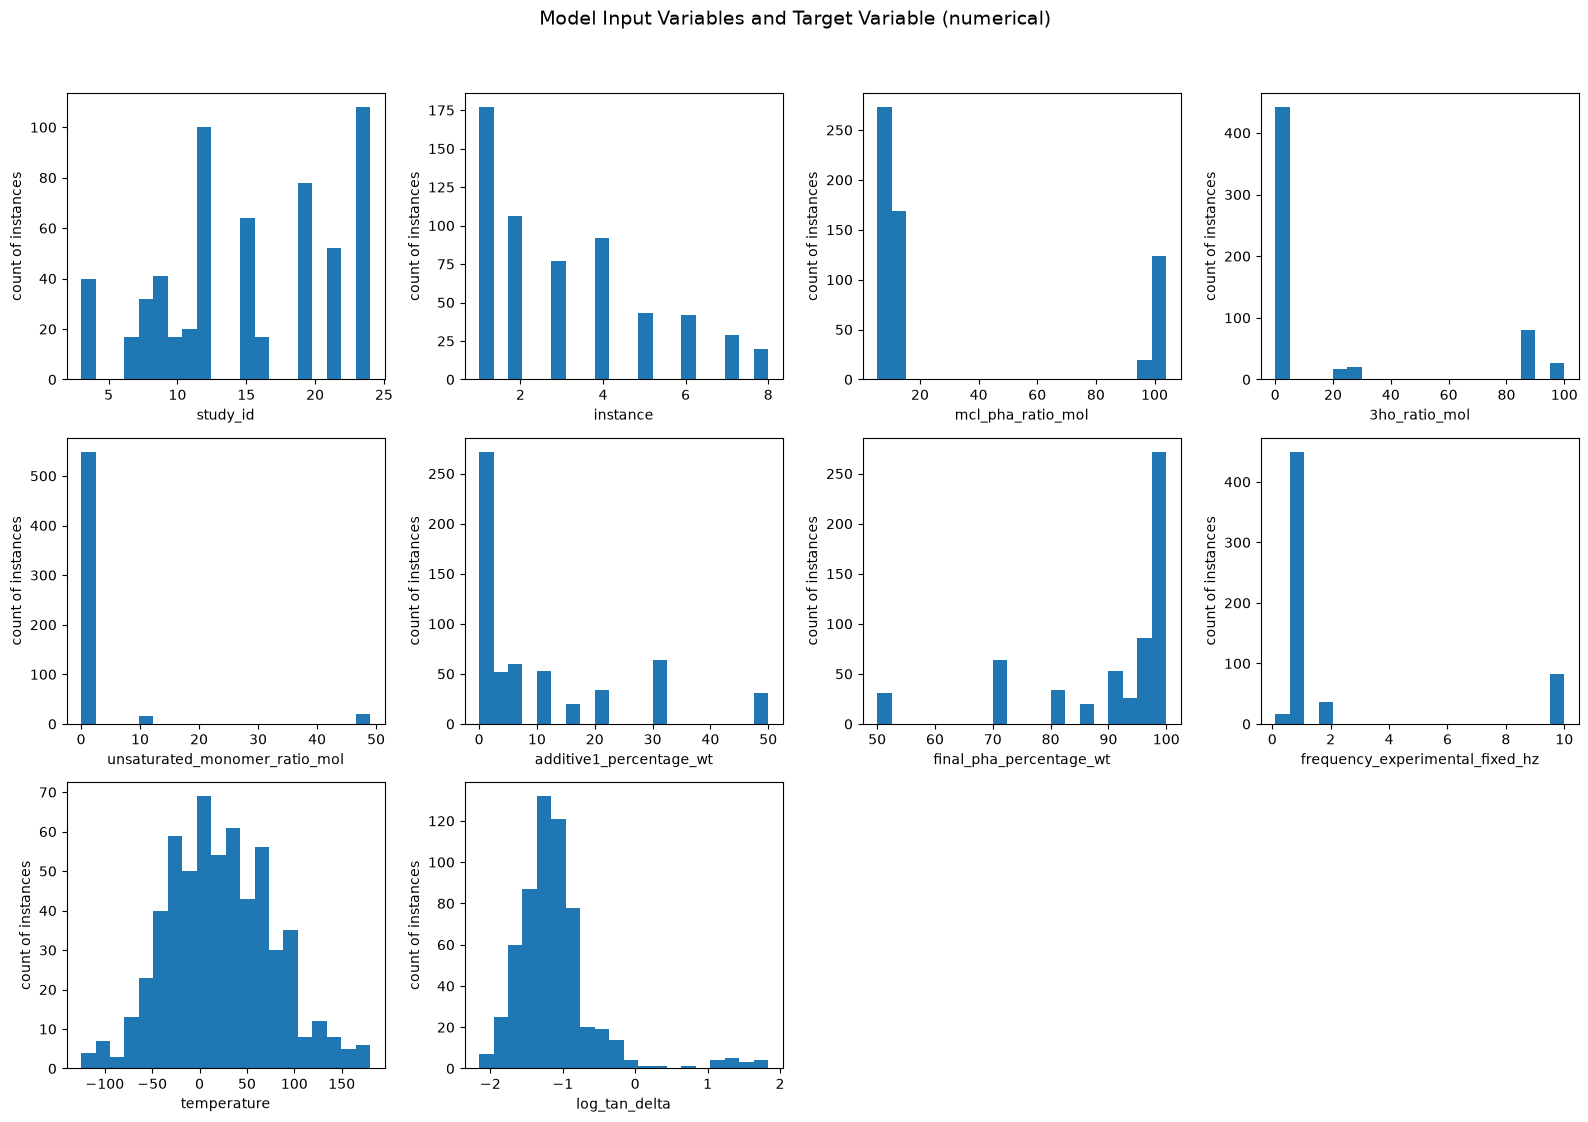

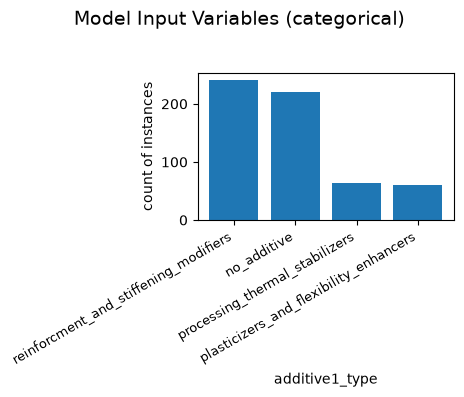

In [35]:
def plot_feature_distributions(
    df: pd.DataFrame,
    numerical_cols,
    categorical_cols,
    title_numeric="Model Input Variables and Target Variable (numerical)",
    title_categorical="Model Input Variables (categorical)",
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,   # cap bars for very high-cardinality cats
):
    # ---------- helper to grid-plot ----------
    def _grid_dims(n, max_cols):
        cols = min(max_cols, max(1, n))
        rows = int(math.ceil(n / cols))
        return rows, cols

    # ---------- NUMERICAL ----------
    if len(numerical_cols) > 0:
        n = len(numerical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.0*cols, 3.8*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_numeric, fontsize=14, y=0.98)

        for i, col in enumerate(numerical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            x = df[col].dropna().values
            ax.hist(x, bins=bins)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ---------- CATEGORICAL ----------
    if len(categorical_cols) > 0:
        n = len(categorical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.6*cols, 4.0*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_categorical, fontsize=14, y=0.98)

        for i, col in enumerate(categorical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            vc = (df[col].astype(str).replace("nan", np.nan)
                                 .value_counts(dropna=False)
                                 .head(top_k_categories))
            ax.bar(range(len(vc)), vc.values)
            ax.set_xticks(range(len(vc)))
            ax.set_xticklabels(vc.index.astype(str), rotation=30, ha="right", fontsize=9)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()



plot_feature_distributions(
    df_final,
    numerical_cols_lst,
    categorical_cols_lst,
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,
)

## Correlation matrix of numerical features

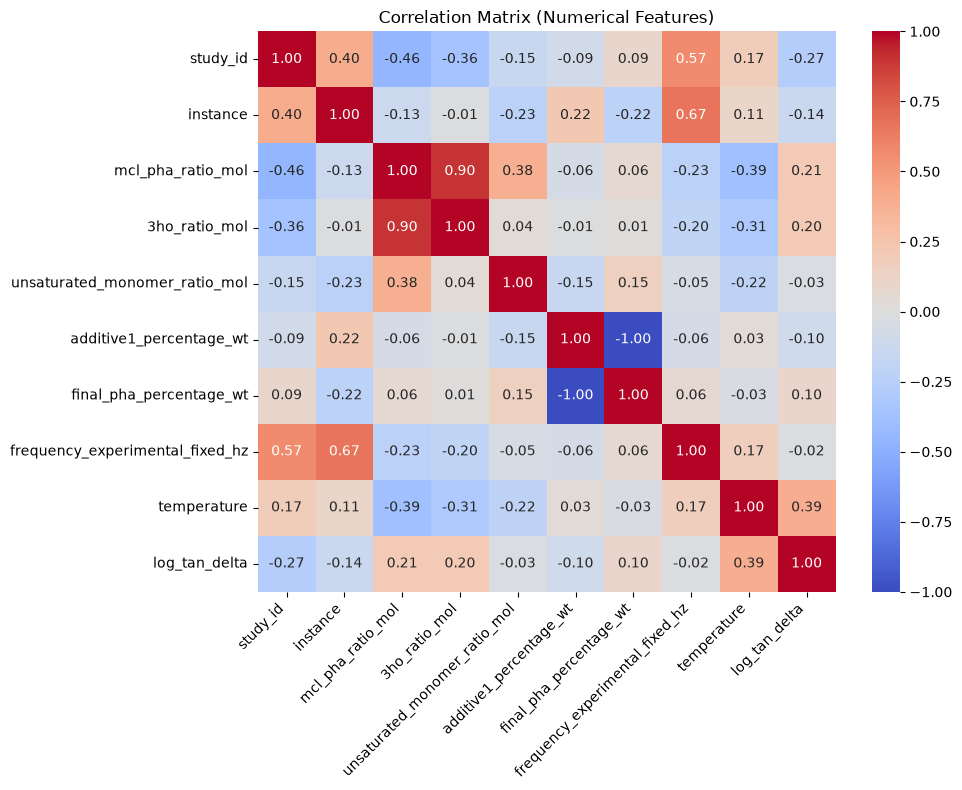

In [40]:
numerical_df = df_final[numerical_cols_lst]

# Compute correlation matrix
corr_matrix = numerical_df.corr() 

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix (Numerical Features)")
plt.xticks(rotation=45, ha="right") 
plt.yticks(rotation=0) 

plt.tight_layout()
# plt.savefig("correlation.tiff", format="tiff", dpi=600, bbox_inches="tight")
plt.show()

## study-aware Train/test splitting

In [42]:
# Split settings
split_method = 'kennard_stone'   # 'random' | 'kennard_stone'
test_size = 0.2

# Encode features for distance
def encode_for_distance(X):

    Xe = pd.get_dummies(
        X,
        columns=[c for c in categorical_cols_lst if c in X.columns],
        dtype=float
    )

    return StandardScaler().fit_transform(Xe)

# Kennard-Stone algorithm
def kennard_stone_split(Z, n_train, y=None):

    D = cdist(Z, Z)

    if y is not None:
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        Dy = cdist(y, y)

        if D.max() > 0:
            D = D / D.max()

        if Dy.max() > 0:
            Dy = Dy / Dy.max()

        D = D + Dy

    # Special case: one training sample
    if n_train == 1:
        centroid = Z.mean(axis=0)
        selected = [np.argmin(np.linalg.norm(Z - centroid, axis=1))]
        remaining = [k for k in range(len(Z)) if k not in selected]

        return np.array(selected), np.array(remaining)

    # Two most distant samples (ensure distinct indices)
    i, j = np.unravel_index(np.argmax(D), D.shape)
    selected = [i, j]

    remaining = [k for k in range(len(Z)) if k not in selected]

    # Iteratively add the sample farthest from the selected set
    while len(selected) < n_train:

        dmin = D[np.ix_(remaining, selected)].min(axis=1)

        k = remaining[int(np.argmax(dmin))]

        selected.append(k)
        remaining.remove(k)

    return np.sort(selected), np.sort(remaining)

# General splitting function
def split_data(X, y, method='kennard_stone',
               test_size=0.2, seed=42):

    n = len(X)

    if isinstance(test_size, float):
        n_test = int(np.ceil(test_size * n))
    else:
        n_test = int(test_size)

    n_test = max(1, n_test)
    n_test = min(n_test, n - 1)

    if method == 'random':

        return train_test_split(
            X, y,
            test_size=test_size,
            random_state=seed
        )

    elif method == 'kennard_stone':

        n_train = n - n_test

        Z = encode_for_distance(X)

        tr, te = kennard_stone_split(Z, n_train)

        return (
            X.iloc[tr],
            X.iloc[te],
            y.iloc[tr],
            y.iloc[te]
        )

    else:
        raise ValueError(
            f"Unknown split method: {method}. "
            "Choose 'random' or 'kennard_stone'."
        )

In [48]:
# Separate features and target
drop_cols = [
    target,
#    'study_id',
#    'instance',
    '3ho_ratio_mol',
#    'uknown_monomer_ratio_mol',
    'final_pha_percentage_wt',
#    'unsaturated_monomer_ratio_mol',
#    'frequency_experimental_fixed_hz'
]

X_train_list, y_train_list = [], []
X_test_list, y_test_list = [], []
X_val_list, y_val_list = [], []

# Per-instance splitting
for (study, instance), df_inst in df_final.groupby(
    ['study_id', 'instance']
):


    # --- Step 1: Validation = highest temperature point(s) among rows with tan_delta < 0.4
    df_candidates = df_inst.copy() # [df_inst['tan_delta'] < 0.4]
    
    if not df_candidates.empty:
        max_temp = df_candidates['temperature'].max()
        df_val_inst = df_candidates[df_candidates['temperature'] == max_temp]
        
        X_val_list.append(df_val_inst.drop(columns=drop_cols))
        y_val_list.append(df_val_inst[target])

    # --- Step 2: Remaining points for train/test
    df_remaining = df_inst[df_inst['temperature'] < max_temp]

    X_remaining = df_remaining.drop(columns=drop_cols)
    y_remaining = df_remaining[target]

    n = len(df_remaining)

    if n >= 2:

        X_train_inst, X_test_inst, y_train_inst, y_test_inst = split_data(
            X_remaining,
            y_remaining,
            method=split_method,
            test_size=test_size,
            seed=42
        )

    elif n == 1:

        # Only one point -> keep it in training
        X_train_inst = X_remaining
        y_train_inst = y_remaining

        X_test_inst = X_remaining.iloc[0:0]
        y_test_inst = y_remaining.iloc[0:0]

    else:

        # No remaining points
        X_train_inst = X_remaining
        y_train_inst = y_remaining

        X_test_inst = X_remaining
        y_test_inst = y_remaining

    X_train_list.append(X_train_inst)
    y_train_list.append(y_train_inst)

    X_test_list.append(X_test_inst)
    y_test_list.append(y_test_inst)


# Concatenate
X_train = pd.concat(X_train_list)
y_train = pd.concat(y_train_list)

X_test = pd.concat(X_test_list)
y_test = pd.concat(y_test_list)

X_val = pd.concat(X_val_list)
y_val = pd.concat(y_val_list)

# Summary
print(f"Split method: {split_method}")
print(f"Train points: {len(X_train)}")
print(f"Test points: {len(X_test)}")
print(f"Validation points: {len(X_val)}")

print("\nUnique studies:")
print("Train:", df_final.loc[X_train.index, 'study_id'].nunique())
print("Test:", df_final.loc[X_test.index, 'study_id'].nunique())
print("Validation:", df_final.loc[X_val.index, 'study_id'].nunique())

Split method: kennard_stone
Train points: 425
Test points: 123
Validation points: 38

Unique studies:
Train: 13
Test: 13
Validation: 13


## Feature importance

In [51]:
def corr_ratio(cat_s, num_s):
    # correlation ratio eta (0-1)
    m = num_s.mean(); sst = ((num_s - m) ** 2).sum()
    ssb = sum(len(v) * (v.mean() - m) ** 2 for _, v in num_s.groupby(cat_s))
    return float(np.sqrt(ssb / sst)) if sst > 0 else 0.0

cat_f = [c for c in X_train.columns if c in categorical_cols_lst]
num_f = [c for c in X_train.columns if c not in cat_f]
for c in cat_f:
    for n_ in num_f:
        print(f'eta({c}, {n_}) = {corr_ratio(X_train[c], X_train[n_]):.2f}')
print('\nrelation with the target (train rows):')
for c in cat_f:
    print(f'  eta({c}, target) = {corr_ratio(X_train[c], y_train):.2f}')
for n_ in num_f:
    print(f'  |Pearson r|({n_}, target) = {abs(np.corrcoef(X_train[n_], y_train)[0, 1]):.2f}')

eta(additive1_type, study_id) = 0.50
eta(additive1_type, instance) = 0.77
eta(additive1_type, mcl_pha_ratio_mol) = 0.34
eta(additive1_type, unsaturated_monomer_ratio_mol) = 0.29
eta(additive1_type, additive1_percentage_wt) = 0.56
eta(additive1_type, frequency_experimental_fixed_hz) = 0.85
eta(additive1_type, temperature) = 0.21

relation with the target (train rows):
  eta(additive1_type, target) = 0.29
  |Pearson r|(study_id, target) = 0.28
  |Pearson r|(instance, target) = 0.16
  |Pearson r|(mcl_pha_ratio_mol, target) = 0.23
  |Pearson r|(unsaturated_monomer_ratio_mol, target) = 0.01
  |Pearson r|(additive1_percentage_wt, target) = 0.11
  |Pearson r|(frequency_experimental_fixed_hz, target) = 0.03
  |Pearson r|(temperature, target) = 0.36


In [53]:
drop_cols = ['unsaturated_monomer_ratio_mol']
for d in (X_train, X_test, X_val):          # whichever frames you have
    d.drop(columns=drop_cols, errors='ignore', inplace=True)
numerical_cols_lst = [c for c in numerical_cols_lst if c not in drop_cols]

## Outlier detection - FAMD + IQR

In [58]:
# Fit FAMD with a reasonably high number of components
famd = FAMD(n_components=30, n_iter=10, random_state=42).fit(X_train)

eigenvalues = famd.eigenvalues_
explained_inertia = eigenvalues / eigenvalues.sum()
cumulative_inertia = np.cumsum(explained_inertia)

famd.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,3.697,14.22%,14.22%
1,2.879,11.07%,25.29%
2,2.251,8.66%,33.95%
3,1.756,6.75%,40.70%
4,1.473,5.66%,46.37%
5,1.358,5.22%,51.59%
6,1.273,4.90%,56.48%
7,1.162,4.47%,60.95%
8,1.082,4.16%,65.12%


In [60]:
# Initial FAMD for outlier detection
n_components_initial = 23
famd2 = FAMD(n_components=n_components_initial, random_state=42)
X_train_famd = famd2.fit_transform(X_train)

X_train_famd.info()

<class 'pandas.DataFrame'>
Index: 425 entries, 0 to 584
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       425 non-null    float64
 1   1       425 non-null    float64
 2   2       425 non-null    float64
 3   3       425 non-null    float64
 4   4       425 non-null    float64
 5   5       425 non-null    float64
 6   6       425 non-null    float64
 7   7       425 non-null    float64
 8   8       425 non-null    float64
 9   9       425 non-null    float64
 10  10      425 non-null    float64
 11  11      425 non-null    float64
 12  12      425 non-null    float64
 13  13      425 non-null    float64
 14  14      425 non-null    float64
 15  15      425 non-null    float64
 16  16      425 non-null    float64
 17  17      425 non-null    float64
 18  18      425 non-null    float64
 19  19      425 non-null    float64
 20  20      425 non-null    float64
 21  21      425 non-null    float64
 22  22      425 non-nu

In [62]:
X_train_famd_df = X_train_famd.copy()
X_train_famd_df.columns = [f'Comp{i+1}' for i in range(X_train_famd_df.shape[1])]

X_train_famd_df.tail()

,Comp1,Comp2,Comp3,Comp4,Comp5,Comp6,Comp7,Comp8,Comp9,Comp10,...,Comp14,Comp15,Comp16,Comp17,Comp18,Comp19,Comp20,Comp21,Comp22,Comp23
576,5.090050,-0.034732,0.886803,1.252552,0.445828,-2.246136,-0.673718,-0.164974,-0.516716,-1.609960,...,-1.530527,0.627545,1.832260,-0.354373,1.693824,-1.376877,0.017310,-0.051013,-0.023306,0.114895
577,5.712705,-0.359867,-0.074888,0.408692,1.079617,-1.382032,-0.880418,0.975682,-0.550355,-1.794294,...,-1.530527,0.672848,2.115581,-0.533700,0.612376,0.966751,0.155902,-0.431767,-0.041475,0.113365
580,5.159234,-0.070858,0.779948,1.158790,0.516249,-2.150125,-0.696684,-0.038234,-0.520454,-1.630442,...,-1.530527,0.632579,1.863740,-0.374299,1.573663,-1.116474,0.032709,-0.093319,-0.025324,0.114725
582,5.228418,-0.106984,0.673094,1.065028,0.586670,-2.054113,-0.719651,0.088505,-0.524191,-1.650923,...,-1.530527,0.637612,1.895220,-0.394224,1.453502,-0.856070,0.048108,-0.135625,-0.027343,0.114555
584,5.297602,-0.143110,0.566239,0.971266,0.657091,-1.958101,-0.742618,0.215245,-0.527929,-1.671405,...,-1.530527,0.642646,1.926701,-0.414149,1.333341,-0.595667,0.063507,-0.177931,-0.029362,0.114385


## Outlier detection with IQR

**Test = 1:** No exclusion
**Test = 2:** +-10 IQR   **Test = 3:** +-7 IQR  

In [66]:
test = 3

# Detect outliers using IQR
def detect_iqr_outliers(df,alpha):
    outlier_indices = set()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - alpha * IQR
        upper_bound = Q3 + alpha * IQR
        outliers_col = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
        outlier_indices.update(outliers_col)
    return list(outlier_indices)

# Drop outliers
if test == 2:
    alpha = 10
    outlier_idx_train = detect_iqr_outliers(X_train_famd_df, alpha)
    X_train_clean = X_train.drop(index=outlier_idx_train)
    y_train_clean = y_train.drop(index=outlier_idx_train)
    print("IQR outlier detection APPLIED with ±2")

elif test == 3:
    alpha = 10
    outlier_idx_train = detect_iqr_outliers(X_train_famd_df, alpha)
    X_train_clean = X_train.drop(index=outlier_idx_train)
    y_train_clean = y_train.drop(index=outlier_idx_train)
    print("IQR outlier detection APPLIED with ±",alpha)

else:
    df_clean = df_final.copy()
    X_train_clean = X_train
    y_train_clean = y_train
    print("IQR outlier detection SKIPPED")

print(f"Original data shape: {X_train.shape}")
print(f"Cleaned data shape: {X_train_clean.shape}")

IQR outlier detection APPLIED with ± 10
Original data shape: (425, 7)
Cleaned data shape: (386, 7)


## One-hot encoding

In [69]:
id_cols = ['study_id', 'instance']

X_train_final = X_train_clean.drop(columns=id_cols)
X_test_final  = X_test.drop(columns=id_cols)

numerical_cols_lst = [
    col for col in numerical_cols_lst
    if col not in id_cols
]

categorical_cols_lst = [
    col for col in categorical_cols_lst
    if col not in id_cols
]

In [71]:
X_train = X_train_final.copy()
X_test = X_test_final.copy()

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop=None)
ohe.fit(X_train[categorical_cols_lst])

# Transform
X_train_ohe = ohe.transform(X_train[categorical_cols_lst])
X_test_ohe = ohe.transform(X_test[categorical_cols_lst])

# Convert to DataFrame with proper column names
ohe_columns = ohe.get_feature_names_out(categorical_cols_lst)
X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe_columns, index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe_columns, index=X_test.index)

In [73]:
# combine
X_train_final = pd.concat([X_train.drop(columns=categorical_cols_lst), X_train_ohe_df], axis=1)
X_test_final = pd.concat([X_test.drop(columns=categorical_cols_lst), X_test_ohe_df], axis=1)

print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")

X_train_final shape: (386, 8)
X_test_final shape: (123, 8)


## RF and XGBoost regression

In [76]:
n_feat = X_train_final.shape[1]

models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=500, max_depth=None, min_samples_split=2, min_samples_leaf=1,
        random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="rmse",
    n_jobs=-1
)
 }

preds = {}
for name, mdl in models.items():
    mdl.fit(X_train_final, y_train_clean)
    preds[name] = {
        'train': mdl.predict(X_train_final),
        'test': mdl.predict(X_test_final),
    }

In [77]:
y_test = y_test.copy()

def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    r = pearsonr(y_true, y_pred)[0] if (len(y_true) > 2 and np.std(y_pred) > 0) else np.nan
    return {
        'R^2 (log)': r2_score(y_true, y_pred),
        'Pearson r (log)': r,
        'RMSE (log)': root_mean_squared_error(y_true, y_pred),
        'MAE (log)': mean_absolute_error(y_true, y_pred),
    }

metrics = []
for name in models:
    for ds, y_true in (('Train', y_train_clean), ('Test', y_test)):
        m = compute_metrics(y_true, preds[name][ds.lower()])
        metrics.append([name, ds, m['R^2 (log)'], m['Pearson r (log)'], m['RMSE (log)'], m['MAE (log)']])

In [78]:
metrics_df = pd.DataFrame(
    metrics,
    columns=['Model', 'Dataset', 'R^2 (log)', 'Pearson r (log)', 'RMSE (log)', 'MAE (log)']
)

print(metrics_df.round(3).to_string(index=False))

        Model Dataset  R^2 (log)  Pearson r (log)  RMSE (log)  MAE (log)
Random Forest   Train      0.974            0.987       0.094      0.053
Random Forest    Test      0.896            0.947       0.186      0.135
      XGBoost   Train      0.979            0.989       0.084      0.045
      XGBoost    Test      0.852            0.924       0.221      0.146


## Grid search

In [83]:
# study id of every row (used for grouped cross-validation)
groups_train = df_final.loc[X_train_final.index, 'study_id']

In [85]:
tuned = {}     # best estimators
summaries = {} # summary tables

def run_grid(name, estimator, param_grid):


    # Kfold
    groups_train = groups_all.loc[X_train_final.index]
    n_splits = int(min(4, groups_train.nunique()))
    folds = 5
    n_repeats = 5
    cv = RepeatedKFold(n_splits=folds, n_repeats=n_repeats, random_state=42)
    
    gs = GridSearchCV(estimator, param_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=1, verbose=0)
    gs.fit(X_train_final, y_train_clean, groups=groups_train)
    best = gs.best_estimator_

    y_tr = best.predict(X_train_final)
    y_te = best.predict(X_test_final)

    # Cross-validation
    cvres = cross_validate(
        best,
        X_train_final,
        y_train_clean,
        cv=cv,
        groups=groups_train,
        scoring={
            'r2': 'r2',
            'rmse': 'neg_root_mean_squared_error',
            'mae': 'neg_mean_absolute_error'
        },
        n_jobs=1
    )

    cv_r2 = cvres['test_r2']
    cv_rmse = -cvres['test_rmse']
    cv_mae = -cvres['test_mae']

    # Summary
    summary = pd.DataFrame({
        'Metric': [
            'Train R²',
            'Test R²',
            'CV Mean R²',
            'CV SD R²',
            'Train RMSE (log)',
            'Test RMSE (log)',
            'CV Mean RMSE (log)',
            'CV SD RMSE (log)',
            'Train MAE (log)',
            'Test MAE (log)',
            'CV Mean MAE (log)',
            'CV SD MAE (log)',
            'Train Pearson r',
            'Test Pearson r'
        ],

        f'{name} (Tuned)': [
            r2_score(y_train_clean, y_tr),
            r2_score(y_test, y_te),
            cv_r2.mean(),
            cv_r2.std(),
            root_mean_squared_error(y_train_clean, y_tr),
            root_mean_squared_error(y_test, y_te),
            cv_rmse.mean(),
            cv_rmse.std(),
            mean_absolute_error(y_train_clean, y_tr),
            mean_absolute_error(y_test, y_te),
            cv_mae.mean(),
            cv_mae.std(),
            pearsonr(y_train_clean, y_tr)[0],
            pearsonr(y_test, y_te)[0]
        ]
    })

    # Store results
    tuned[name] = best
    summaries[name] = summary

    preds[f'{name} (tuned)'] = {
        'train': y_tr,
        'test': y_te
    }

    # Print results
    print(f"\nBest parameters found ({name}):")
    print(gs.best_params_)

    print(f"\nBest CV RMSE (log): {-gs.best_score_:.3f}")

    print("\nPerformance summary:")
    print(summary.round(3).to_string(index=False))

    return best

In [87]:
param_grid = {
    'n_estimators': [100, 200, 500],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2, 4]
}
best_rf = run_grid('Random Forest', RandomForestRegressor(random_state=42, n_jobs=1), param_grid)
best_params = best_rf.get_params()


Best parameters found (Random Forest):
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV RMSE (log): 0.198

Performance summary:
            Metric  Random Forest (Tuned)
          Train R²                  0.971
           Test R²                  0.895
        CV Mean R²                  0.849
          CV SD R²                  0.099
  Train RMSE (log)                  0.098
   Test RMSE (log)                  0.186
CV Mean RMSE (log)                  0.198
  CV SD RMSE (log)                  0.047
   Train MAE (log)                  0.060
    Test MAE (log)                  0.135
 CV Mean MAE (log)                  0.128
   CV SD MAE (log)                  0.021
   Train Pearson r                  0.986
    Test Pearson r                  0.947


In [89]:
study = df_final.loc[X_train_final.index, 'study_id'].reset_index(drop=True)
sample = df_final.loc[X_train_final.index, 'instance'].reset_index(drop=True)
study_sample = study.astype(str) + '_' + sample.astype(str)      # unique id: instance numbers repeat across studies

class MultiSampleLOIO:
    """Leave-one-instance-out, only for instances whose study has >1 sample."""
    def __init__(self, study, sample):
        self.study, self.sample = np.asarray(study), np.asarray(sample)
        n = pd.Series(self.sample).groupby(self.study).nunique()
        self.multi = set(n[n > 1].index)
        self.instances = [s for s in pd.unique(self.sample) if self.study[self.sample == s][0] in self.multi]
    def split(self, X=None, y=None, groups=None):
        for inst in self.instances:
            yield np.where(self.sample != inst)[0], np.where(self.sample == inst)[0]

cv_loio = MultiSampleLOIO(study, study_sample)

Xr, yr = X_train_final.reset_index(drop=True), np.asarray(y_train_clean)
mask = np.zeros(len(yr), bool); oof = np.full(len(yr), np.nan)
for tr, te in cv_loio.split():
    m = clone(best_rf).fit(Xr.iloc[tr], yr[tr])
    oof[te] = m.predict(Xr.iloc[te]); mask[te] = True                 # no clipping

print(f"LOIO: n={mask.sum()}  R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.3f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.3f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

LOIO: n=362  R2=0.433  RMSE=0.288  MAE=0.163  r=0.753


## Plot results

In [91]:
# Predictions
y_train_pred_grid = best_rf.predict(X_train_final)
y_test_pred_grid = best_rf.predict(X_test_final)

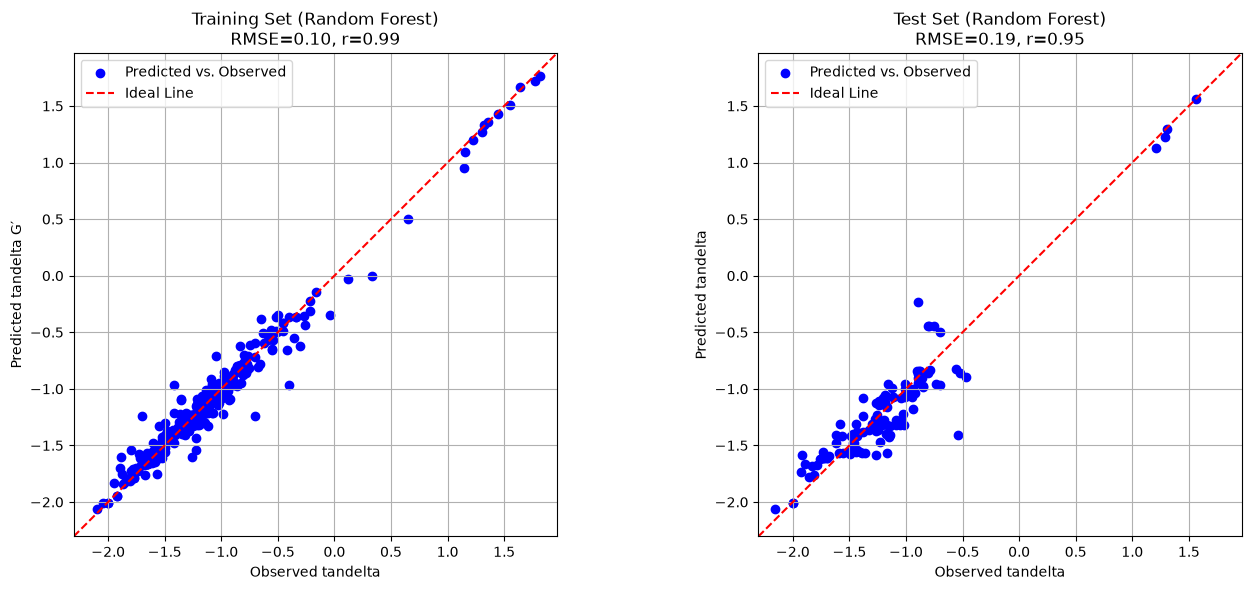

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # width doubled for 2 plots

# common axis limits so both panels are comparable
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid, y_test_pred_grid])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed tandelta')
axes[0].set_ylabel('Predicted tandelta G\u2032')
axes[0].set_title(f'Training Set (Random Forest)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
axes[1].scatter(y_test, y_test_pred_grid, color='blue', label='Predicted vs. Observed')
axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed tandelta')
axes[1].set_ylabel('Predicted tandelta')
axes[1].set_title(f'Test Set (Random Forest)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("mcl_dts_tan_rf_pair_grid.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Plot RMSE w.r.t No of trees

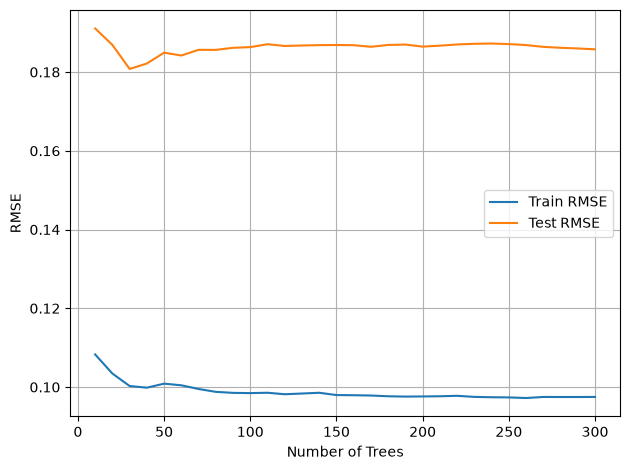

In [95]:
train_rmse = []
test_rmse = []

n_estimators_range = range(10, 301, 10)

for n in n_estimators_range:
    rf = RandomForestRegressor(
        n_estimators=n,
        max_depth=best_params['max_depth'],
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_final, y_train_clean)

    y_train_pred = rf.predict(X_train_final)
    y_test_pred = rf.predict(X_test_final)

    train_rmse.append(root_mean_squared_error(y_train_clean, y_train_pred))
    test_rmse.append(root_mean_squared_error(y_test, y_test_pred))

plt.figure()
plt.plot(n_estimators_range, train_rmse, label="Train RMSE")
plt.plot(n_estimators_range, test_rmse, label="Test RMSE")
plt.xlabel("Number of Trees")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("mcl_dts_tan_rmse.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance

In [97]:
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_final)     # array shape: (n_samples, n_features)
base_value = explainer.expected_value

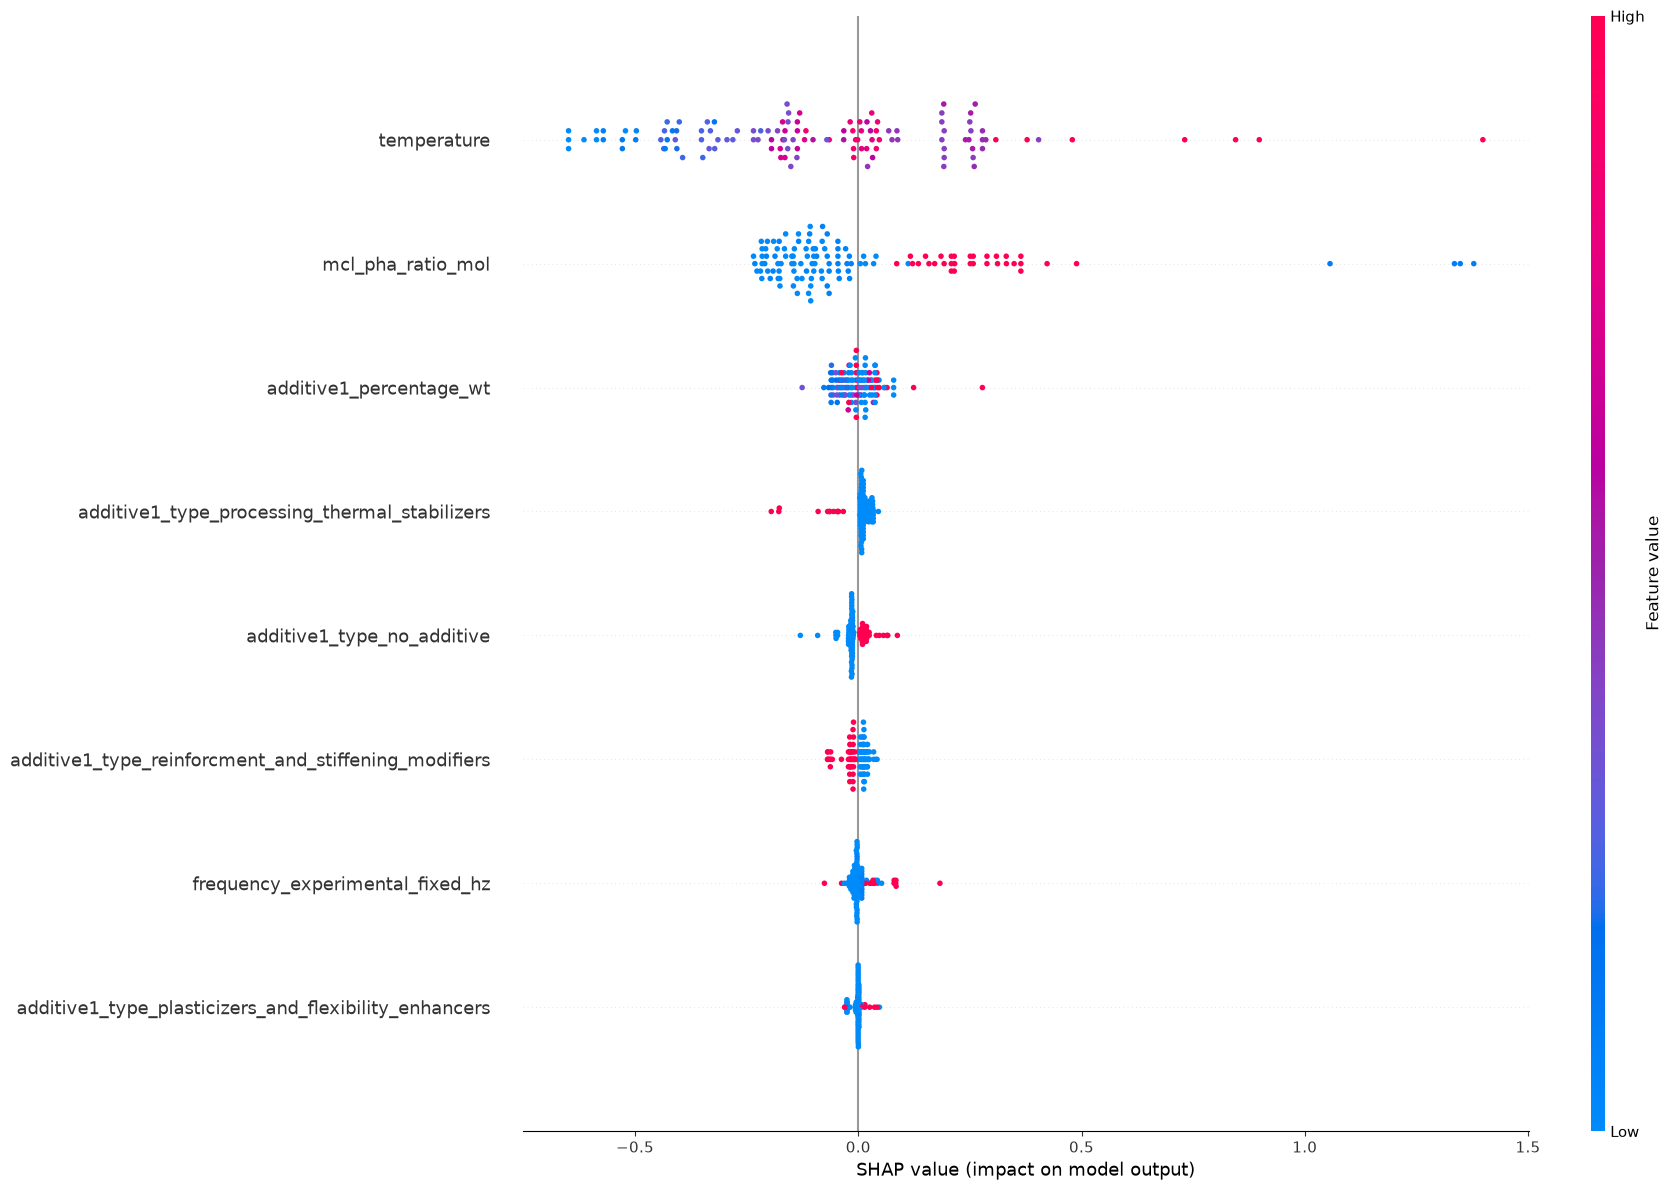

In [99]:
shap.summary_plot(
    shap_values,
    X_test_final,
#    max_display=10,        # <-- top 10 features only
    show=False,
    plot_size=(18, 12)
)

plt.tight_layout()
plt.savefig("mcl_dts_tan_rf_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Grid search - XGBoost

In [101]:
param_grid = {
       'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.01],
    'max_depth': [4, 6],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.7, 0.8]
}
best_xgb = run_grid('XGBoost', XGBRegressor(random_state=42, n_jobs=1), param_grid)
best_params2 = best_xgb.get_params()


Best parameters found (XGBoost):
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}

Best CV RMSE (log): 0.187

Performance summary:
            Metric  XGBoost (Tuned)
          Train R²            0.975
           Test R²            0.832
        CV Mean R²            0.871
          CV SD R²            0.080
  Train RMSE (log)            0.092
   Test RMSE (log)            0.236
CV Mean RMSE (log)            0.187
  CV SD RMSE (log)            0.041
   Train MAE (log)            0.056
    Test MAE (log)            0.151
 CV Mean MAE (log)            0.119
   CV SD MAE (log)            0.018
   Train Pearson r            0.987
    Test Pearson r            0.914


In [103]:
for tr, te in cv_loio.split():
    m = clone(best_xgb).fit(Xr.iloc[tr], yr[tr])
    oof[te] = m.predict(Xr.iloc[te]); mask[te] = True                 # no clipping

print(f"LOIO: n={mask.sum()}  R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.3f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.3f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

LOIO: n=362  R2=0.409  RMSE=0.294  MAE=0.176  r=0.722


## Plot results

In [105]:
# Predictions
y_train_pred_grid2 = best_xgb.predict(X_train_final)
y_test_pred_grid2 = best_xgb.predict(X_test_final)

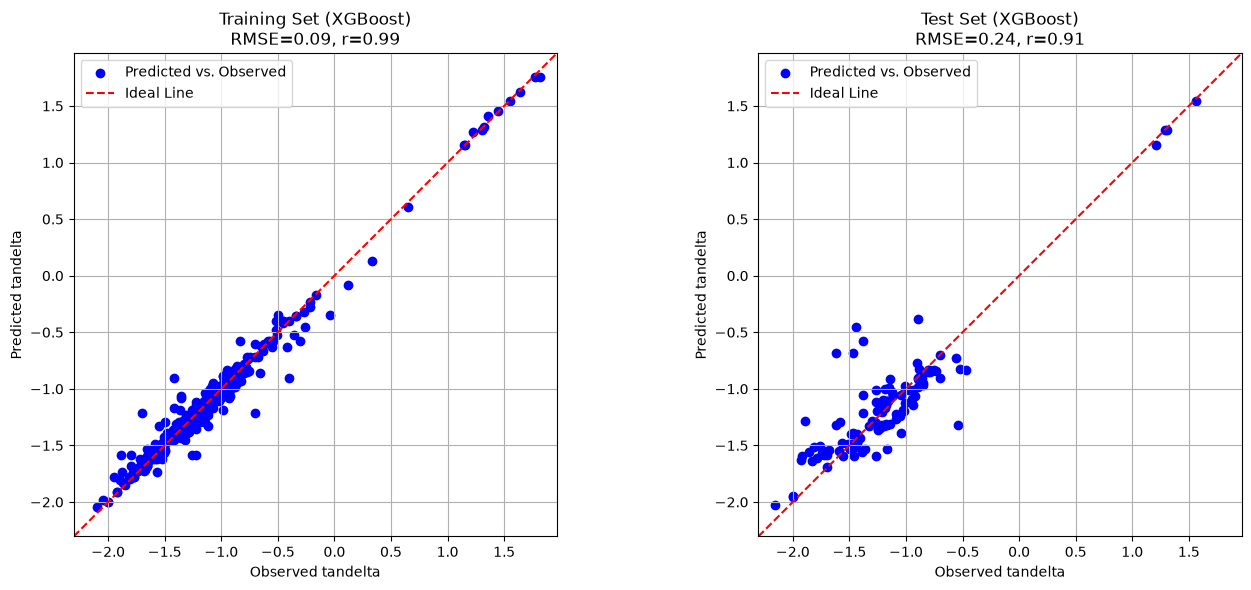

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # width doubled for 2 plots

# common axis limits so both panels are comparable
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid2, y_test_pred_grid2])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid2, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed tandelta')
axes[0].set_ylabel('Predicted tandelta')
axes[0].set_title(f'Training Set (XGBoost)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid2):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid2)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
axes[1].scatter(y_test, y_test_pred_grid2, color='blue', label='Predicted vs. Observed')
axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed tandelta')
axes[1].set_ylabel('Predicted tandelta')
axes[1].set_title(f'Test Set (XGBoost)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid2):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid2)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("mcl_dts_tan_xgb_pair_grid.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Loss plot

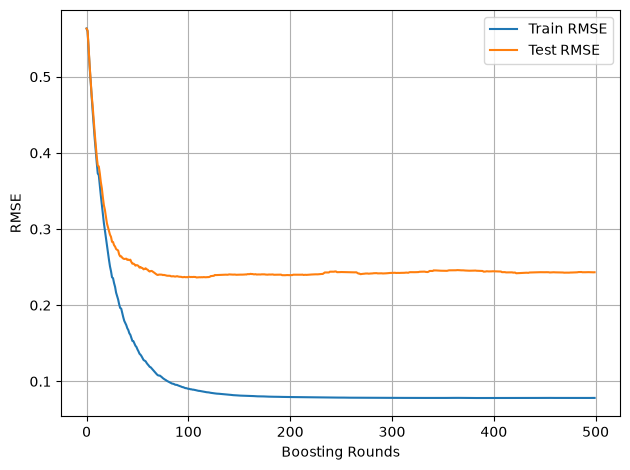

In [109]:
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=best_params['max_depth'],
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric=["rmse"],
    random_state=42
)

model.fit(
    X_train_final, y_train_clean,
    eval_set=[(X_train_final, y_train_clean), (X_test_final, y_test)],
    verbose=False
)

results = model.evals_result()

epochs = len(results['validation_0']['rmse'])

plt.figure()
plt.plot(range(epochs), results['validation_0']['rmse'], label="Train RMSE")
plt.plot(range(epochs), results['validation_1']['rmse'], label="Test RMSE")
plt.xlabel("Boosting Rounds")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("mcl_dts_tan_xgb_loss.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance

In [111]:
explainer2 = shap.TreeExplainer(best_xgb)
shap_values2 = explainer2.shap_values(X_test_final)     # array shape: (n_samples, n_features)
base_value2 = explainer2.expected_value

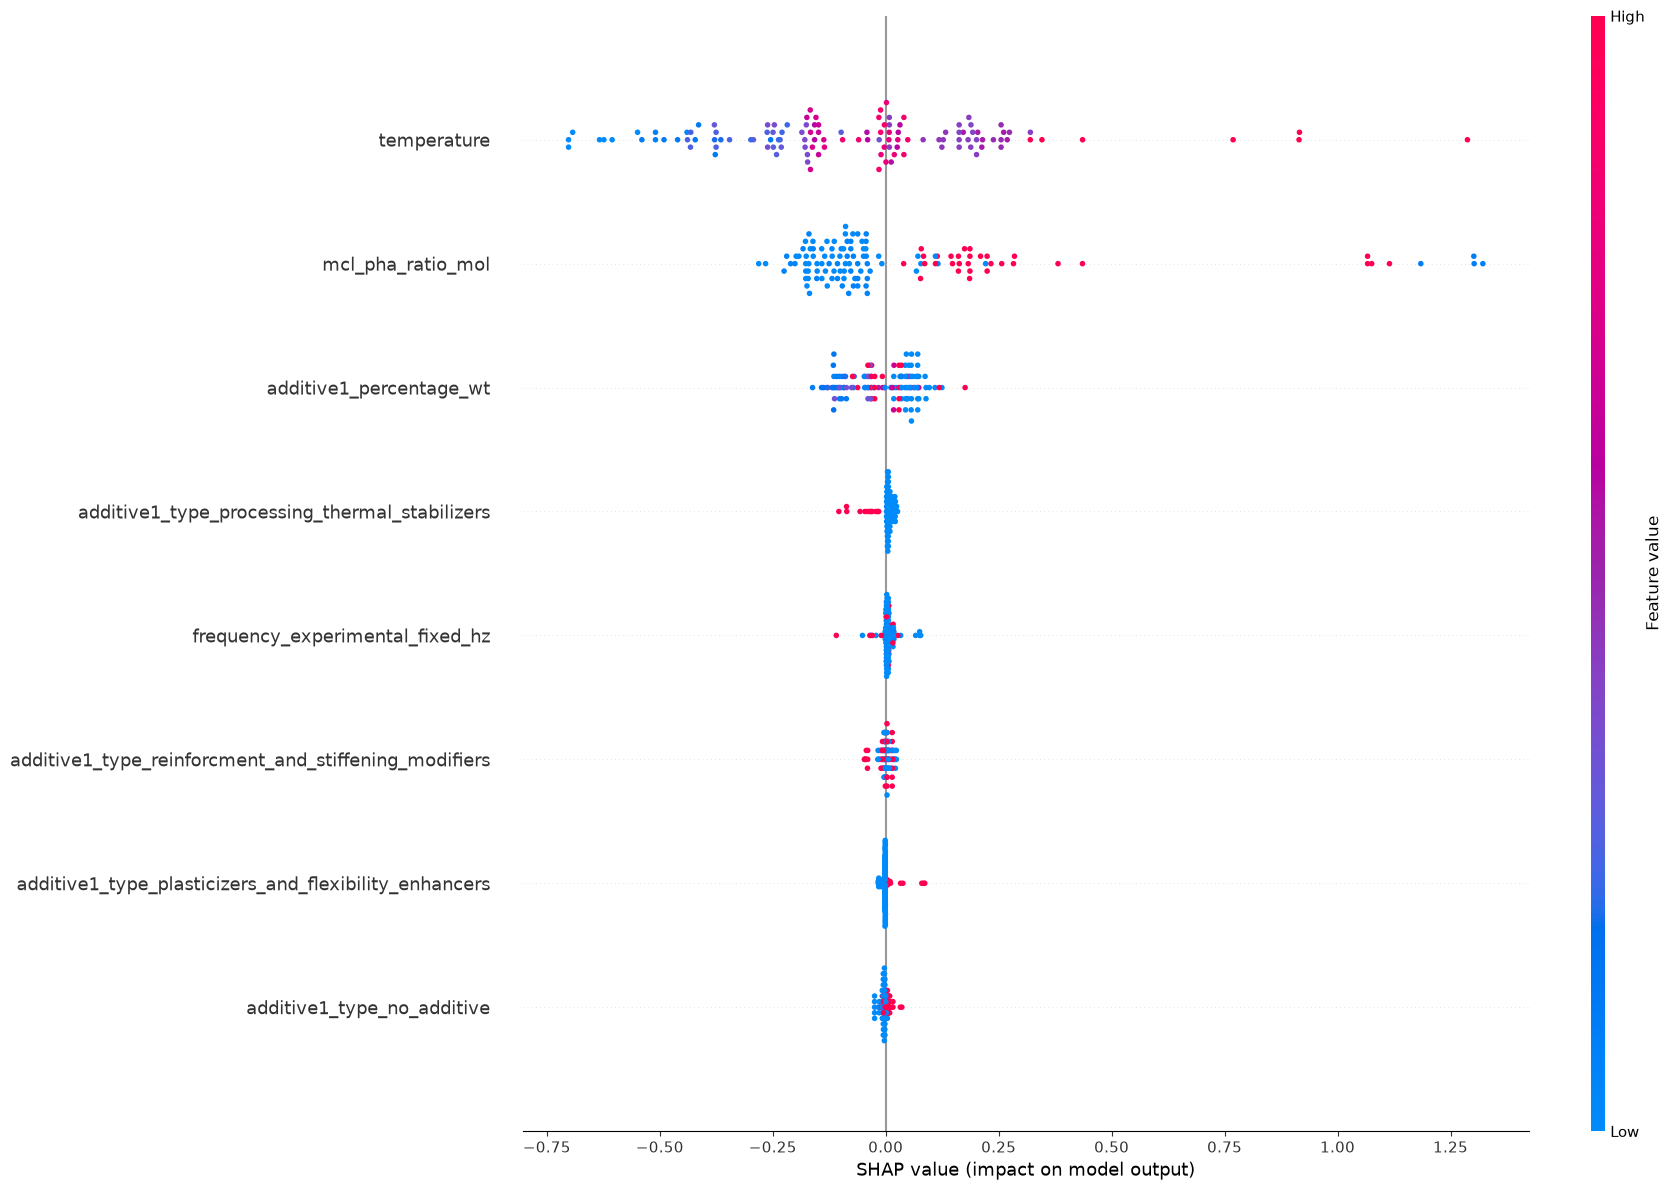

In [113]:
shap.summary_plot(
    shap_values2,
    X_test_final,
#    max_display=10,        # <-- top 10 features only
    show=False,
    plot_size=(18, 12)
)

plt.tight_layout()
plt.savefig("mcl_dts_tan_xgb_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Validation check on unseen data (excl. full instances)

In [115]:
X_val.columns

Index(['study_id', 'instance', 'mcl_pha_ratio_mol', 'additive1_percentage_wt',
       'frequency_experimental_fixed_hz', 'additive1_type', 'temperature'],
      dtype='str')

In [117]:
X_val  = X_val.drop(columns=id_cols)

In [119]:
X_val_ohe = ohe.transform(X_val[categorical_cols_lst])
X_val_ohe_df = pd.DataFrame(X_val_ohe, columns=ohe_columns, index=X_val.index)
X_val_final = pd.concat([X_val.drop(columns=categorical_cols_lst), X_val_ohe_df], axis=1)

In [121]:
cols = X_val_final.columns.tolist()
first_col = cols.pop(0)

# Insert it at index 2 (third position)
cols.insert(2, first_col)
# X_val_final = X_val_final[cols]
# y_val = df_val[target]

# RF
y_val_pred_rf = best_rf.predict(X_val_final)
r_rf,_ = pearsonr(y_val, y_val_pred_rf)
rmse_rf = root_mean_squared_error(y_val, y_val_pred_rf)
r2_rf = r2_score(y_val, y_val_pred_rf)
print(f'Pearson on unseen set (RF): {r_rf}')
print(f'RMSE on unseen set (RF): {rmse_rf:.3f}')
print(f'R2 on unseen set (RF): {r2_rf:.3f}')


# XGBoost
y_val_pred_xg = best_xgb.predict(X_val_final)
r_xg,_ = pearsonr(y_val, y_val_pred_xg)
rmse_xg = root_mean_squared_error(y_val, y_val_pred_xg)
r2_xg = r2_score(y_val, y_val_pred_xg)
print(f'Pearson on unseen set (XGB): {r_xg}')
print(f'RMSE on unseen set (XGB): {rmse_xg:.3f}')
print(f'R2 on unseen set (XGB): {r2_xg:.3f}')

Pearson on unseen set (RF): 0.8742456194061701
RMSE on unseen set (RF): 0.295
R2 on unseen set (RF): 0.727
Pearson on unseen set (XGB): 0.8172453781744013
RMSE on unseen set (XGB): 0.331
R2 on unseen set (XGB): 0.658


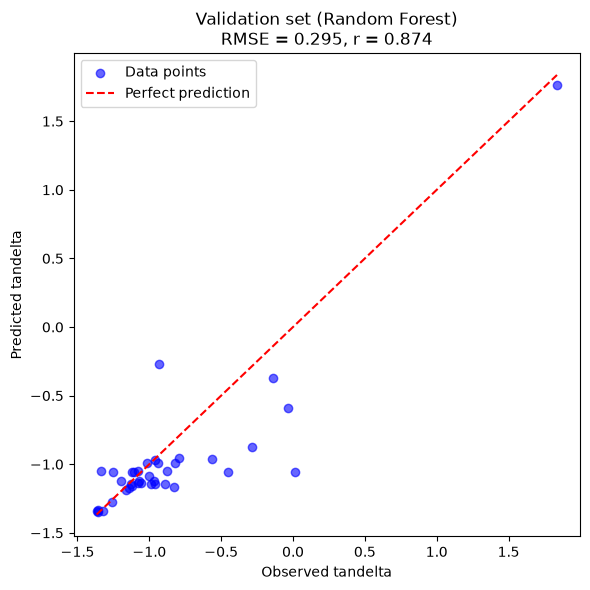

In [123]:
# Scatter plot
plt.figure(figsize=(6,6))
plt.scatter(y_val, y_val_pred_rf, color='blue', alpha=0.6, label='Data points')

# Perfect prediction line
min_val = min(y_val.min(), y_val_pred_rf.min())
max_val = max(y_val.max(), y_val_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect prediction')

# Add labels and title if needed
plt.xlabel('Observed tandelta')
plt.ylabel('Predicted tandelta')
plt.title(f'Validation set (Random Forest)\n'
    f'RMSE = {rmse_rf:.3f}, r = {r_rf:.3f}')
plt.legend()

plt.tight_layout()
plt.savefig("mcl_dts_tan_rf_unseen.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

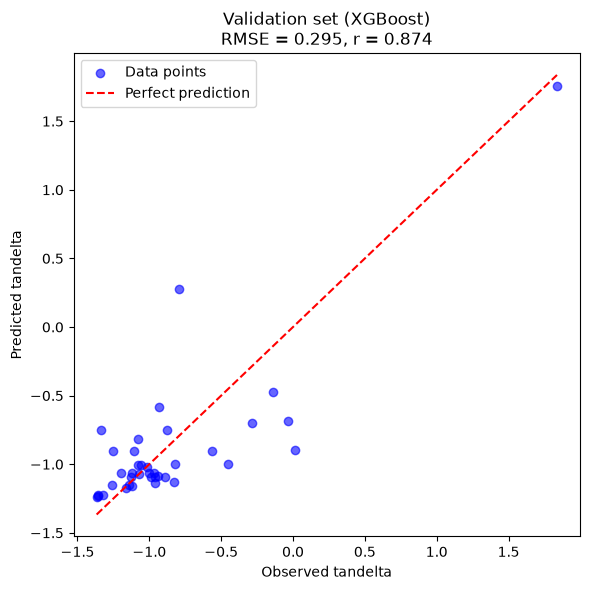

In [125]:
## Scatter plot
plt.figure(figsize=(6,6))
plt.scatter(y_val, y_val_pred_xg, color='blue', alpha=0.6, label='Data points')

# Perfect prediction line
min_val = min(y_val.min(), y_val_pred_xg.min())
max_val = max(y_val.max(), y_val_pred_xg.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect prediction')

# Add labels and title if needed
plt.xlabel('Observed tandelta')
plt.ylabel('Predicted tandelta')
plt.title(f'Validation set (XGBoost)\n'
    f'RMSE = {rmse_rf:.3f}, r = {r_rf:.3f}')
plt.legend()

plt.tight_layout()
plt.savefig("mcl_dts_tan_xg_unseen.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Jaqpot

In [127]:
df_stor.columns

Index(['study_id', 'instance', '3hb_ratio_mol', '3ho_ratio_mol',
       '3hdd_ratio_mol', '3hv_ratio_mol', 'mcl_pha_ratio_mol',
       '3httd_ratio_mol', 'unsaturated_monomer_ratio_mol',
       'uknown_monomer_ratio_mol', 'additive1_percentage_wt', 'additive1_type',
       'final_pha_percentage_wt', 'frequency_experimental_fixed_hz',
       'temperature', 'tan_delta', 'log_tan_delta'],
      dtype='str')

In [135]:
features = [
#    'unsaturated_monomer_ratio_mol',
    'mcl_pha_ratio_mol',
#    '3ho_ratio_mol',
#    'final_pha_percentage_wt',
    'additive1_type',
    'additive1_percentage_wt',
    'frequency_experimental_fixed_hz',
    'temperature'
]

target = 'tan_delta'

measure_unit = ' '

In [137]:
# Create DataFrame
df_new = df_stor[features + [target]]

# Drop rows with N/A value
mask = (
    df_new[target].notna() &
    df_new[features].notna().all(axis=1)
)

# Create final dataset
df_final = df_new.loc[mask, features + [target]].copy()
df_final[target] = np.log10(df_final[target])  # log-transform
df_final.columns = df_final.columns.str.replace(' ', '_', regex=False)

In [139]:
def to_object(df):
    df = df.copy()
    for c in df.columns:
        if str(df[c].dtype) in ('str', 'string', 'string[python]', 'string[pyarrow]'):
            df[c] = df[c].astype(object)
    return df

df_final = to_object(df_final)

df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 586 entries, 0 to 585
Data columns (total 6 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   mcl_pha_ratio_mol                586 non-null    float64
 1   additive1_type                   586 non-null    object 
 2   additive1_percentage_wt          586 non-null    float64
 3   frequency_experimental_fixed_hz  586 non-null    float64
 4   temperature                      586 non-null    float64
 5   tan_delta                        586 non-null    float64
dtypes: float64(5), object(1)
memory usage: 27.6+ KB


In [141]:
# Separate features and target
drop_cols = [target]

X = df_final.drop(columns=drop_cols)
y = df_final[target]

In [143]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42
)

print('Train set size:', X_train.shape, '\n Test set size',X_test.shape)

Train set size: (498, 5) 
 Test set size (88, 5)


In [145]:
numerical_cols_lst = (
    df_final
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)

categorical_cols_lst = (
    df_final
    .select_dtypes(include=['object', 'category'])
    .columns
    .tolist()
)

In [147]:
numerical_cols_lst.remove(target)
features_num = numerical_cols_lst
features_cat = categorical_cols_lst

In [149]:
df_train = X_train.copy()
df_train[target] = y_train

train_dataset = JaqpotTabularDataset(
    df=df_train,
    x_cols=X_train.columns.to_list(),
    y_cols=target,
    task="REGRESSION",
)

df_test = X_test.copy()
df_test[target] = y_test

test_dataset = JaqpotTabularDataset(
    df=df_test,
    x_cols=X_test.columns.to_list(),
    y_cols=target,
    task="REGRESSION",
)

In [151]:
preprocessing = ColumnTransformer(
    transformers=[
        ('numerical_features', StandardScaler(), features_num),
        ('categorical_features', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='if_binary'), features_cat)
    ],
    remainder='drop',
)

In [153]:
model = RandomForestRegressor(random_state=42, max_depth=10, min_samples_leaf=1, min_samples_split=2, n_estimators=100)
jaqpot_model = SklearnModel(
    dataset=train_dataset,
    model=model,
    doa=[Leverage(), BoundingBox()],
    preprocess_x=preprocessing,
  )

jaqpot_model.random_seed = 1231
jaqpot_model.fit()

Goodness-of-fit metrics on training set:
{'r2': 0.9678716855184633, 'mae': 0.06308994347541201, 'rmse': 0.10507855233752873}


In [155]:
# Perform cross-validation on the training data
jaqpot_model.cross_validate(train_dataset, n_splits=10)

{'r2': 0.8135120853239963,
 'mae': 0.11751679907665133,
 'rmse': 0.19048105191090012}

In [157]:
# Evaluate the model on the test dataset
jaqpot_model.evaluate(test_dataset)

{'r2': 0.8300932507816637,
 'mae': 0.12757762879371287,
 'rmse': 0.20602309511845224}

In [159]:
# Conducts a randomization test to assess the model's robustness
jaqpot_model.randomization_test(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    n_iters=10,
)

{'iteration_0': {'Train': {'r2': 0.548573932253774,
   'mae': 0.2547950964878354,
   'rmse': 0.39387954430439376},
  'Test': {'r2': -0.32783892567440986,
   'mae': 0.41664653274980845,
   'rmse': 0.5759480204484138}},
 'iteration_1': {'Train': {'r2': 0.6419966731161313,
   'mae': 0.23549789499409113,
   'rmse': 0.3507628911522477},
  'Test': {'r2': -0.49661829602554874,
   'mae': 0.44963017342069667,
   'rmse': 0.6114572757732247}},
 'iteration_2': {'Train': {'r2': 0.6605918774263665,
   'mae': 0.24252031923532893,
   'rmse': 0.3415318617538},
  'Test': {'r2': -0.35969615836995206,
   'mae': 0.40193978390165347,
   'rmse': 0.582816082321441}},
 'iteration_3': {'Train': {'r2': 0.5825035877680061,
   'mae': 0.25939932325852394,
   'rmse': 0.3787882368654791},
  'Test': {'r2': -0.629284331067508,
   'mae': 0.4620440515719817,
   'rmse': 0.637982891277634}},
 'iteration_4': {'Train': {'r2': 0.6642524342654837,
   'mae': 0.24247478101319903,
   'rmse': 0.3396851381631831},
  'Test': {'r2': 

In [161]:
doa_predictions = jaqpot_model.predict_doa(test_dataset)
print(doa_predictions)

{'LEVERAGE': [{'h': np.float64(0.06011772187423618), 'hStar': 0.05421686746987952, 'inDoa': False}, {'h': np.float64(0.02050078162665932), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.056642999478522665), 'hStar': 0.05421686746987952, 'inDoa': False}, {'h': np.float64(0.010731379828580731), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.009678672393714616), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.015329952262029354), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.019774812883972676), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.00842529533343311), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.022474111411273548), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.008398815030206088), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.02181489944971525), 'hStar': 0.05421686746987952, 'inDoa': True}, {'h': np.float64(0.03056840013046461), 'hS

In [163]:
summary = {}
for key in ['LEVERAGE','BOUNDING_BOX']:
    df_doa = pd.DataFrame(doa_predictions[key])
    summary[key] = {
        'n_total': len(df_doa),
        'n_in': int(df_doa['inDoa'].sum()),
        'n_out': int((~df_doa['inDoa']).sum())
    }
summary

{'LEVERAGE': {'n_total': 88, 'n_in': 84, 'n_out': 4},
 'BOUNDING_BOX': {'n_total': 88, 'n_in': 88, 'n_out': 0}}

In [165]:
# Upload the pretrained model on Jaqpot
jaqpot = Jaqpot()
jaqpot.login()
jaqpot_model.deploy_on_jaqpot(
    jaqpot=jaqpot,
    name="Tan delta regression model for mcl-PHAs A.N.I.P.H.",
    description="Prediction of log-transformed tan delta for mcl-PHAs using Dynamic Temperature Sweep (DTS) data. To convert to actual loss tangent: tan delta = 10^(predicted value).",
    visibility="PUBLIC",
)

Open this URL in your browser and log in:
https://login.jaqpot.org/realms/jaqpot/protocol/openid-connect/auth?client_id=jaqpot-client&response_type=code&redirect_uri=urn:ietf:wg:oauth:2.0:oob&scope=openid email profile&state=random_state_value&nonce=


Enter the authorization code you received:  ········


  2026-11-17 11:31:34,401 - INFO - Model has been successfully uploaded. The url of the model is https://app.jaqpot.org/dashboard/models/2427
